<a href="https://colab.research.google.com/github/Nasim-Amani/solar/blob/main/2solar_data_final_columns.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

df = pd.read_csv("solar_data_SolarRad_clean.csv")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1015991 entries, 0 to 1015990
Data columns (total 15 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   DateTime         1015991 non-null  object 
 1   Amb_Tempr        1015991 non-null  float64
 2   Solar_Rad        1015991 non-null  float64
 3   Tempr_PV_1       1015991 non-null  float64
 4   Tempr_PV_2       1015991 non-null  float64
 5   Tempr_PV_3       1015991 non-null  float64
 6   PV_1_SA_V        1015991 non-null  float64
 7   PV_4_Hor_V       1015991 non-null  float64
 8   PV_1_SA_I        1015991 non-null  float64
 9   PV_2_GT_I        1015991 non-null  float64
 10  PV_3_Tr_I        1015991 non-null  float64
 11  PV_4_Hor_I       1015991 non-null  float64
 12  full_day         1015991 non-null  bool   
 13  Solar_Rad_clean  1015991 non-null  float64
 14  daylight         1015991 non-null  bool   
dtypes: bool(2), float64(12), object(1)
memory usage: 102.7+ MB


,min,max,mean_night,mean_day,std_day,unique_values,r_with_GHI_day
Amb_Tempr,15.447,31.768,20.375,23.376,2.602,7677,0.568
Tempr_PV_1,8.145,62.279,13.156,33.397,11.841,18382,0.904
Tempr_PV_2,7.486,56.493,12.320,32.313,11.742,17199,0.898
Tempr_PV_3,8.713,59.031,13.494,29.828,9.889,16603,0.887
PV_1_SA_V,0.000,43.112,0.431,39.528,3.295,27150,0.493
PV_4_Hor_V,-0.618,20.821,-0.614,15.352,5.493,38710,0.865
PV_1_SA_I,-0.115,-0.008,-0.083,-0.086,0.021,57,0.022
PV_2_GT_I,-0.014,10.168,0.038,4.285,2.690,20958,0.995
PV_3_Tr_I,-0.015,15.319,0.022,0.278,1.905,2551,0.158
PV_4_Hor_I,-0.192,1.536,0.008,0.106,0.138,3074,0.221


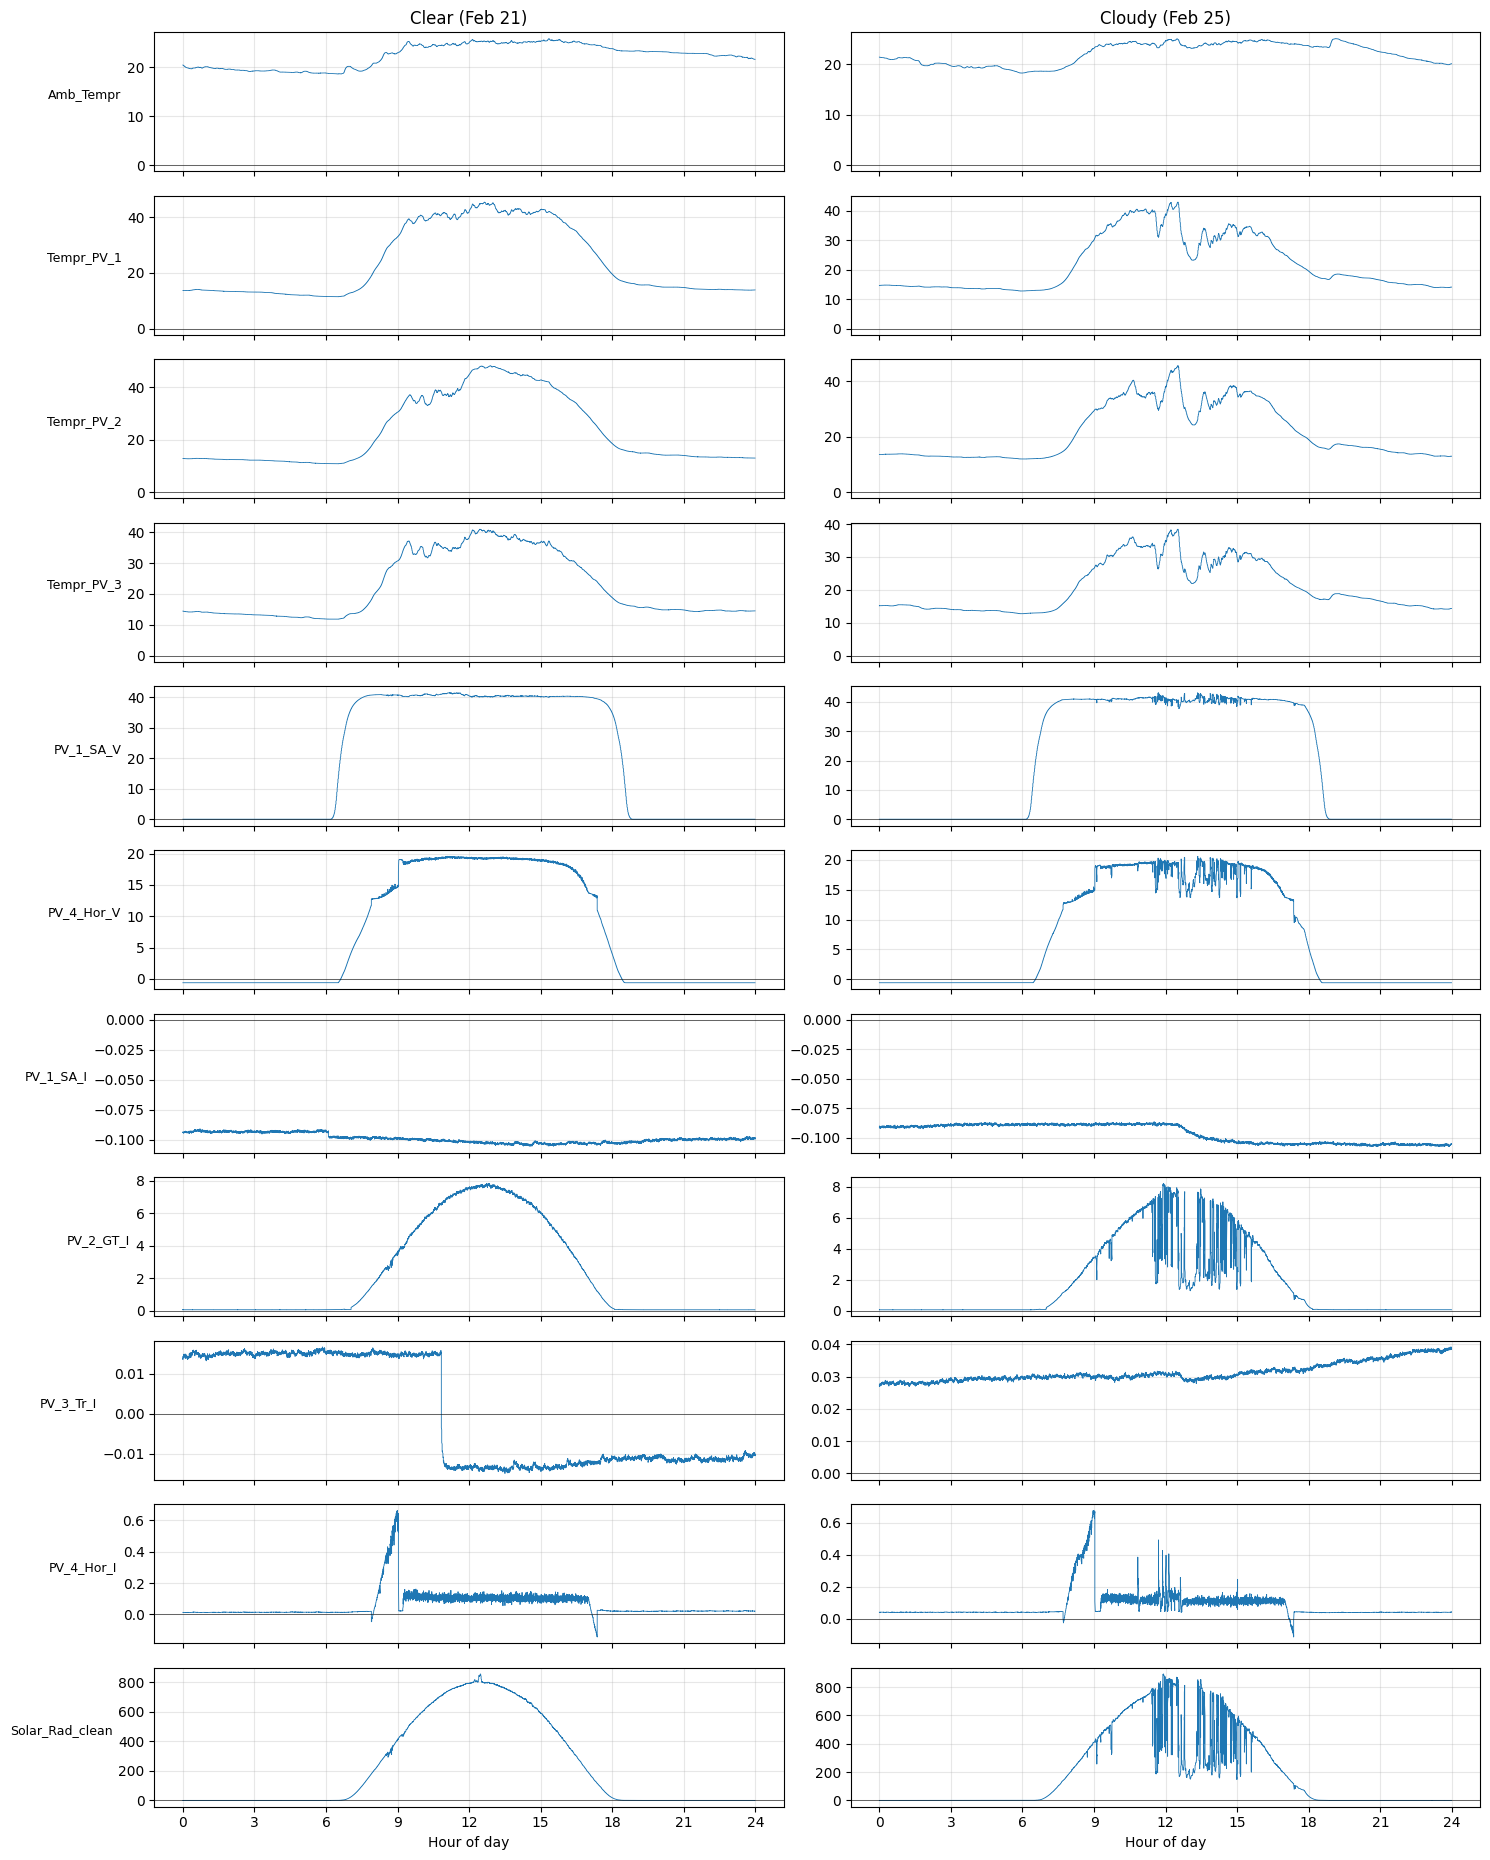

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)

# ---- Load ----
df = pd.read_csv("solar_data_SolarRad_clean.csv")
df["DateTime"] = pd.to_datetime(df["DateTime"], format="%Y-%m-%d %H:%M:%S")
df = df.set_index("DateTime").sort_index()

sensors = [c for c in df.select_dtypes("number").columns if c != "Solar_Rad"]
day, night = df["daylight"], ~df["daylight"]

# ---- 1) One-line profile per sensor ----
m1 = df.loc[day, sensors].resample("1min").mean().dropna()      # 1-min means, daylight only
profile = pd.DataFrame({
    "min":            df[sensors].min(),
    "max":            df[sensors].max(),
    "mean_night":     df.loc[night, sensors].mean(),
    "mean_day":       df.loc[day, sensors].mean(),
    "std_day":        df.loc[day, sensors].std(),
    "unique_values":  df[sensors].nunique(),
   # "%_same_as_prev": df[sensors].eq(df[sensors].shift()).mean() * 100,
    "r_with_GHI_day": m1.corr()["Solar_Rad_clean"],
}).round(3)
display(profile)

# ---- 2) All sensors on one clear and one cloudy day (10-s means) ----
days = {"Clear (Feb 21)": "2013-02-21", "Cloudy (Feb 25)": "2013-02-25"}
fig, axes = plt.subplots(len(sensors), 2, figsize=(15, 1.7 * len(sensors)), sharex="col")
for j, (title, d) in enumerate(days.items()):
    x = df.loc[d, sensors].resample("10s").mean()
    hours = x.index.hour + x.index.minute / 60
    for i, col in enumerate(sensors):
        ax = axes[i, j]
        ax.plot(hours, x[col], lw=0.6)
        ax.axhline(0, color="k", lw=0.4)
        if j == 0:
            ax.set_ylabel(col, rotation=0, ha="right", fontsize=9)
        ax.grid(alpha=0.3)
    axes[0, j].set_title(title)
    axes[-1, j].set_xticks(range(0, 25, 3))
    axes[-1, j].set_xlabel("Hour of day")
plt.tight_layout()
plt.show()

## 1. Column Profile: Which Sensors Are Useful?

### What the code does
1. Builds **one summary row per sensor**, separately for day and night (using the `daylight` flag):

| Metric | What it checks |
|---|---|
| `min`, `max` | Is the range physically sensible? |
| `mean_night` vs `mean_day` | Does the sensor respond to the sun? Is there a night offset? |
| `std_day` | Does it vary during the day, or is it flat? |
| `unique_values` | Is the sensor alive? (very few values = dead or stuck) |
| `r_with_GHI_day` | Correlation with `Solar_Rad_clean` in daylight (1-min means): how closely it follows sunlight |

2. **Plots every sensor** on one clear day (Feb 21) and one cloudy day (Feb 25). A sensor driven by sunlight should show a smooth curve on the clear day and follow the cloud dips on the cloudy day.

### Interpretation

**✅ Working and useful**
- **Solar_Rad_clean:** the cleaned reference irradiance (night ≈ 0, daytime mean 456 W/m²).
- **PV_2_GT_I (r = 0.995):** the best PV signal. It ranges from 0 to 10 A, is ≈ 0 at night, and follows irradiance and every cloud almost perfectly, so it acts as a second irradiance sensor.
- **Tempr_PV_1/2/3 (r ≈ 0.89–0.90):** module temperatures rise from ~13 °C at night to ~30–33 °C on average during the day (max ~56–62 °C). They follow the sun **with a delay** (thermal inertia) and react to passing clouds on Feb 25.
- **Amb_Tempr (r = 0.57):** air temperature varies only ~3 °C between night and day. It responds slowly and only partly to sunlight, so a moderate correlation is expected.

**⚠️ Working, but measuring something different**
- **PV_1_SA_V:** ~0 V at night and a nearly constant ~40 V during the day (low std), while PV_1 current is ~0. The panel is most likely at **open circuit**, so this voltage is **Voc**. It jumps up at sunrise and stays flat, which explains the low correlation (0.49).
- **PV_4_Hor_V / PV_4_Hor_I:** behave like a **small 12 V panel charging a battery through a charge controller**. Current rises until ~09:00 (charging), then drops to ~0.1 A while voltage jumps from ~13 V to ~19 V (battery full, panel disconnected); this reverses at ~17:30. The voltage follows the daily cycle (r = 0.87), but the current reflects **controller operation, not weather** (r = 0.22). The voltage also has a small night offset (−0.61 V).

**❌ Not useful as they are**
- **PV_1_SA_I:** dead. Only 57 unique values, constant at about −0.09 A day and night, no response to the sun (r = 0.02).
- **PV_3_Tr_I:** almost zero on both plotted days (±0.03 A), with a sudden step on Feb 21. However, its max (15.3 A) and daytime std (1.9 A) show that it **worked on some days**, so a per-day check is needed before deciding.

### Note
- **PV temperatures at night (~13 °C) are ~7 °C below ambient (~20 °C).** Panels can cool below air temperature under a clear night sky, but 7 °C is large. The ambient sensor may be sheltered.

### Conclusion
**Usable set:** `Solar_Rad_clean`, `PV_2_GT_I`, `Tempr_PV_1/2/3`, `Amb_Tempr`, and `PV_1_SA_V` (as Voc).
**Next check:** on which days `PV_3_Tr_I` was working.

#Is PV_1_SA_V really the open-circuit voltage (Voc)?

Physics says the open-circuit voltage of a panel depends on two things in a known way:

* it rises with the logarithm of irradiance (fast at low light, then almost flat), and
* it falls with module temperature, by about −0.3 to −0.5 % per °C for silicon panels.

So we fit Voc = a + b·ln(G) + c·T_module. If the fit is very good and the temperature coefficient lands in that normal range, the “Voc” explanation is confirmed.

Fit: Voc = a + b·ln(G) + c·T_PV1   (1-min means, G > 20 W/m²)
  b (irradiance) = +2.171 V per ln(W/m²)
  c (temperature) = -0.1312 V/°C  = -0.325 %/°C
  R² = 0.904
Night mean: 0.431 V


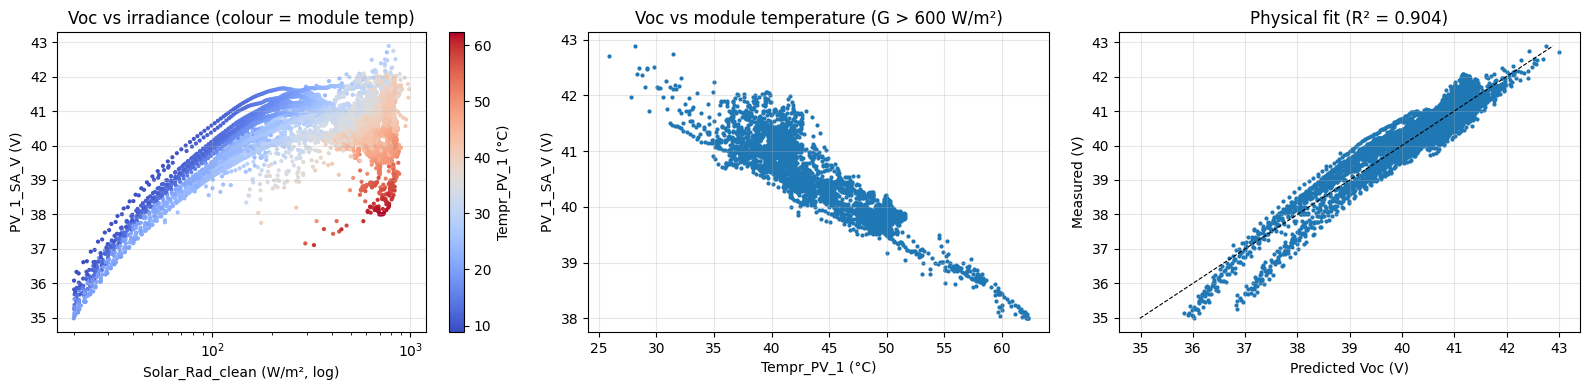

In [5]:
# ===== PV_1: is PV_1_SA_V really the open-circuit voltage (Voc)? =====
# Physics: Voc ≈ a + b·ln(G) + c·T_module   (b > 0, c < 0, typically about −0.3 %/°C)
pv1 = df.loc[df["daylight"] & (df["Solar_Rad_clean"] > 20),
             ["PV_1_SA_V", "Solar_Rad_clean", "Tempr_PV_1"]].resample("1min").mean().dropna()

X = np.column_stack([np.ones(len(pv1)), np.log(pv1["Solar_Rad_clean"]), pv1["Tempr_PV_1"]])
coef, *_ = np.linalg.lstsq(X, pv1["PV_1_SA_V"], rcond=None)
pred = X @ coef
r2 = 1 - ((pv1["PV_1_SA_V"] - pred) ** 2).sum() / ((pv1["PV_1_SA_V"] - pv1["PV_1_SA_V"].mean()) ** 2).sum()
voc_mean = pv1["PV_1_SA_V"].mean()

print("Fit: Voc = a + b·ln(G) + c·T_PV1   (1-min means, G > 20 W/m²)")
print(f"  b (irradiance) = {coef[1]:+.3f} V per ln(W/m²)")
print(f"  c (temperature) = {coef[2]:+.4f} V/°C  = {100 * coef[2] / voc_mean:+.3f} %/°C")
print(f"  R² = {r2:.3f}")
print(f"Night mean: {df.loc[~df['daylight'], 'PV_1_SA_V'].mean():.3f} V")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sc = ax[0].scatter(pv1["Solar_Rad_clean"], pv1["PV_1_SA_V"], c=pv1["Tempr_PV_1"], s=4, cmap="coolwarm")
ax[0].set_xscale("log"); ax[0].set_xlabel("Solar_Rad_clean (W/m², log)"); ax[0].set_ylabel("PV_1_SA_V (V)")
ax[0].set_title("Voc vs irradiance (colour = module temp)"); fig.colorbar(sc, ax=ax[0], label="Tempr_PV_1 (°C)")

hi = pv1[pv1["Solar_Rad_clean"] > 600]
ax[1].scatter(hi["Tempr_PV_1"], hi["PV_1_SA_V"], s=4)
ax[1].set_xlabel("Tempr_PV_1 (°C)"); ax[1].set_ylabel("PV_1_SA_V (V)")
ax[1].set_title("Voc vs module temperature (G > 600 W/m²)")

ax[2].scatter(pred, pv1["PV_1_SA_V"], s=4)
lims = [pv1["PV_1_SA_V"].min(), pv1["PV_1_SA_V"].max()]
ax[2].plot(lims, lims, "k--", lw=0.8)
ax[2].set_xlabel("Predicted Voc (V)"); ax[2].set_ylabel("Measured (V)")
ax[2].set_title(f"Physical fit (R² = {r2:.3f})")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 2. PV_1_SA_V: Confirmation as Open-Circuit Voltage (Voc)

### What we did
Because PV_1's current is ~0, its voltage was expected to be the **open-circuit voltage (Voc)**. Physically, Voc of a PV module:
- **increases with the logarithm of irradiance** (G), and
- **decreases linearly with module temperature** (T), typically by **−0.29 to −0.35 %/°C** for crystalline silicon.

We therefore fitted the physical model **Voc = a + b·ln(G) + c·T_PV1** to 1-min daylight means (G > 20 W/m²) and inspected the relations in three plots. Each point in the plots is one minute.

### Results

| Parameter | Value | Expected |
|---|---|---|
| b (irradiance effect) | +2.17 V per ln(W/m²) | Positive (logarithmic rise) |
| c (temperature effect) | −0.131 V/°C = **−0.325 %/°C** | −0.29 to −0.35 %/°C (c-Si) |
| R² | **0.904** | High |
| Night mean | 0.43 V | ≈ 0 |

### Interpretation of the plots

**Left plot: Voc vs irradiance (log scale), coloured by module temperature**
- At low light, Voc **rises steeply and almost linearly on the log scale**, from ~35 V at 20 W/m² to ~41 V at ~200 W/m². This is the **logarithmic dependence** expected from PV physics.
- Above ~200 W/m² the curve **flattens**, and at high irradiance (> 600 W/m²) Voc even **decreases** (to 38–40 V). This is because the panel heats up in strong sun, and higher temperature lowers Voc.
- **The colours show the temperature effect directly:** at the same irradiance, cool minutes (blue) have a higher Voc than hot minutes (red).
- The several **parallel bands** at low light correspond to different days and to morning vs afternoon, when the panel temperature differs at the same irradiance.
- A few scattered warm points at 37–38 V around 300 W/m² are likely moments **just after a cloud** arrived: irradiance dropped quickly, but the panel was still hot.

**Middle plot: Voc vs module temperature (G > 600 W/m² only)**
- Restricting the data to strong sun keeps irradiance roughly constant, so the **temperature effect is isolated**.
- The points form a clear **descending straight line**: Voc falls from ~42.5 V at ~28 °C to ~38 V at ~62 °C, a slope of about **−0.13 V/°C**, matching the fitted coefficient (−0.325 %/°C).
- The vertical spread (~1 V at 35–45 °C) comes from the remaining irradiance variation (600–1,000 W/m²) and the slow response of the temperature sensor.

**Right plot: measured vs predicted Voc**
- Most points lie close to the **1:1 line** (dashed), so the simple physical model explains **90% of the variation** (R² = 0.904).
- **Small remaining deviations:** at weak light (early morning and late afternoon) the points split into two lines, and one lies slightly below the 1:1 line (measured Voc 0.5–1 V lower than predicted). A likely reason is that the irradiance sensor is mounted **flat**, while PV panels are usually mounted **at an angle**. When the sun is low, an angled panel receives different light than the flat sensor shows, and the difference changes between morning and afternoon. A slow response of the temperature sensor may also contribute. These effects are small and do not change the conclusion.

**Night offset:** a small residual of 0.43 V (physically 0 V).

### Conclusion
- The **temperature coefficient (−0.325 %/°C) is typical of crystalline silicon**, and Voc follows the expected logarithmic irradiance dependence. Together, these confirm that `PV_1_SA_V` is the module's **open-circuit voltage**.
- `PV_1_SA_V` is a **valid Voc measurement** and is **kept**. It is useful as an indicator of the module's thermal and electrical state and for estimating the temperature coefficient.
- `PV_1_SA_I` remains unusable (open circuit, ~0 A).

#Is PV_4 controlled by a battery charge controller?

We split each daylight second into two states using the voltage:

* charging: V below 17 V, so the panel is held at battery voltage (~12–15 V) and current flows.
* disconnected: V at 17 V or above, so the panel is near open circuit and almost no current flows.

Then we check whether each state behaves as the controller explanation predicts, and when the switch happens each day.

,% of records,V mean,I mean,P mean (W),"r(I, GHI)","r(V, GHI)"
state,,,,,,
night,51.632,-0.614,0.008,-0.005,0.048,0.827
charging,19.446,9.906,0.114,1.581,0.819,0.805
disconnected,28.922,19.013,0.101,1.922,0.076,0.710


,Charging start,Disconnect,V before (1-min median),Peak I (A),GHI at disconnect,Charge (Ah)
Date,,,,,,
2013-02-16,08:09:06,09:24:50,14.90,0.901,515.5,0.683
2013-02-17,08:08:28,09:02:19,15.04,0.680,438.6,0.335
2013-02-18,07:45:47,09:02:46,14.31,0.807,318.9,0.242
2013-02-19,08:09:22,09:01:28,15.04,0.611,419.3,0.299
2013-02-20,08:01:22,09:06:05,15.11,0.670,418.6,0.331
2013-02-21,08:03:24,09:03:24,14.79,0.689,423.2,0.359
2013-02-22,08:00:43,08:55:45,15.11,0.714,449.5,0.352
2013-02-23,07:59:17,08:58:05,14.98,0.701,440.3,0.380
2013-02-24,07:59:33,09:02:13,14.84,0.702,424.0,0.402


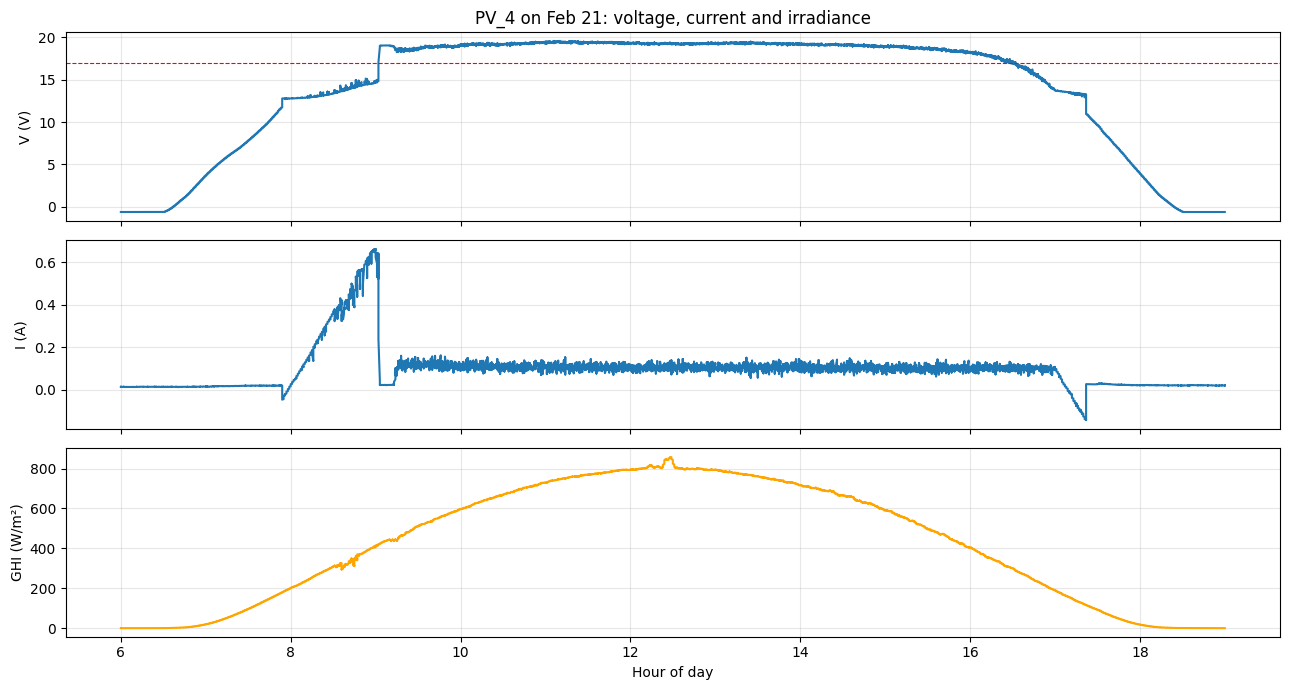

In [8]:
# ===== PV_4: charge-controller behaviour? =====
V, I, G = df["PV_4_Hor_V"], df["PV_4_Hor_I"], df["Solar_Rad_clean"]
V_SWITCH = 17.0   # above this the panel is (near) open circuit; below it, it is held at battery voltage

state = pd.Series("night", index=df.index)
state[df["daylight"] & (V < V_SWITCH)] = "charging"
state[df["daylight"] & (V >= V_SWITCH)] = "disconnected"
df["PV4_state"] = state
df["PV_4_Hor_P"] = V * I                       # power (W)

# ---- 1) Behaviour in each state ----
rows = []
for s in ["night", "charging", "disconnected"]:
    m = state == s
    rows.append({"state": s, "% of records": 100 * m.mean(),
                 "V mean": V[m].mean(), "I mean": I[m].mean(), "P mean (W)": df.loc[m, "PV_4_Hor_P"].mean(),
                 "r(I, GHI)": I[m].corr(G[m]), "r(V, GHI)": V[m].corr(G[m])})
display(pd.DataFrame(rows).set_index("state").round(3))

# ---- 2) When does the controller switch each day? (1-min median of V ignores short spikes) ----
Vs = V.rolling("1min").median()
dl = df[df["daylight"]]
sw = []
for date, d in dl.groupby(dl.index.date):
    vs = Vs.loc[d.index]
    above = vs[vs >= V_SWITCH]
    if above.empty:
        continue
    t = above.index[0]                                   # sustained disconnect
    before = d.loc[:t]
    charging = before[before["PV_4_Hor_I"] > 0.05]       # seconds with real charging current
    start = charging.index[0] if len(charging) else pd.NaT
    sw.append({"Date": date,
               "Charging start": start.strftime("%H:%M:%S") if pd.notna(start) else None,
               "Disconnect": t.strftime("%H:%M:%S"),
               "V before (1-min median)": round(vs.loc[:t - pd.Timedelta("1min")].iloc[-1], 2),
               "Peak I (A)": round(before["PV_4_Hor_I"].max(), 3),
               "GHI at disconnect": round(G[t], 1),
               "Charge (Ah)": round(charging["PV_4_Hor_I"].sum() / 3600, 3)})
display(pd.DataFrame(sw).set_index("Date"))


# ---- 3) One day in detail ----
d = df.loc["2013-02-21 06:00":"2013-02-21 19:00"].resample("10s").mean(numeric_only=True)
h = d.index.hour + d.index.minute / 60
fig, ax = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
ax[0].plot(h, d["PV_4_Hor_V"]); ax[0].axhline(V_SWITCH, ls="--", c="r", lw=0.8); ax[0].set_ylabel("V (V)")
ax[1].plot(h, d["PV_4_Hor_I"]); ax[1].set_ylabel("I (A)")
ax[2].plot(h, d["Solar_Rad_clean"], c="orange"); ax[2].set_ylabel("GHI (W/m²)")
ax[2].set_xlabel("Hour of day"); ax[0].set_title("PV_4 on Feb 21: voltage, current and irradiance")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3. PV_4: Battery Charge-Controller Behaviour

### Background
In a small off-grid system, a solar panel charges a battery through a **charge controller**. The controller protects the battery:
- **Panel voltage below battery voltage:** the panel cannot charge, so it stays disconnected.
- **Charging:** the panel is connected and its voltage is held at the battery voltage (~12–15 V for a 12 V battery). The current depends on sunlight.
- **Battery full** (14.4–15 V for lead-acid): the controller **disconnects** the panel. With no load, the panel voltage rises to its open-circuit level (~19–21 V for a small "12 V" panel) and almost no current flows.

The PV_4 plots (Section 1) looked exactly like this: voltage stuck at ~13–15 V early in the morning, then a jump to ~19 V and a drop in current at ~09:00. We therefore tested whether PV_4 is controlled by such a device.

### What we did and why

**Step 1: Classify each second into a state**
- *What:* each daylight second was labelled **charging** (V < 17 V) or **disconnected** (V ≥ 17 V). Night seconds were labelled **night**. 17 V lies between the battery level (≤ 15 V) and the open-circuit level (~19 V).
- *Why:* if a controller is present, the panel behaves completely differently in the two states, so they must be analysed separately.
- *Expected:* while **charging**, current should **follow irradiance** (high correlation). When **disconnected**, current should be **unrelated to irradiance** (correlation ≈ 0) and voltage should stay near ~19 V.

**Step 2: Find the daily switch from charging to disconnected**
- *What:* for each day we found the first time the voltage stayed above 17 V, using a 1-min median so short spikes are ignored. We also recorded the voltage just before the switch, the charging start time, the peak current, the irradiance at the switch, and the total charge delivered (Ah).
- *Why:* a controller disconnects when the **battery is full**, so the switch should be triggered by **battery voltage**, not by the clock or the weather.
- *Expected:* the voltage just before the switch should be **similar every day (~14.4–15 V)**, while the switch time and irradiance may vary somewhat.

**Step 3: Inspect one clear day in detail (Feb 21)**
- *What:* voltage, current and irradiance were plotted together (10-s means).
- *Why:* to see the full daily sequence of states and check it against irradiance.

*Feb 27 start time is affected by a short noise spike and is not reliable.*

### Interpretation

**States (Step 1)**
- While **charging**, current follows irradiance (**r = 0.82**). When **disconnected**, it does not (**r = 0.08**). This is exactly the expected controller behaviour.
- The disconnected voltage (~19 V) matches the open-circuit voltage of a small "12 V" panel.
- The charging state also includes the early-morning waiting period (current ≈ 0), which lowers its average voltage (9.9 V) and current (0.11 A).
- **The panel is small:** peak power ≈ 0.65 A × 15 V ≈ **10 W**, and mean power is below 2 W.

**Daily cycle (Step 2)**
- **Charging runs from ~08:00 to ~09:00 every day.**
- The voltage just before the disconnect is **14.3–15.1 V on every day**, the typical "full" level of a 12 V lead-acid battery. The controller is therefore **voltage-driven**: it stops when the battery is full.
- **Only 0.24–0.68 Ah is charged per morning**, so the battery is nearly full at sunrise and is used very little at night.
- Feb 16 needed the most charge (0.68 Ah) and disconnected latest (09:25), consistent with a controller that charges until the battery is full.

**Daily sequence on Feb 21 (Step 3)**
1. **06:30–07:55, waiting:** voltage rises slowly (0 → 12 V) with ~0 A. The panel voltage is still below the battery voltage.
2. **07:55–09:00, charging:** voltage is held at battery level (12.8 → 15 V), and current rises from 0 to ~0.65 A **following irradiance**.
3. **~09:00, battery full:** current drops to ~0.1 A and voltage jumps to ~19 V. The panel is disconnected.
4. **09:00–16:30, idle:** voltage (~19 V) and current (~0.1 A) stay flat and **no longer respond to irradiance** (800 W/m² at noon gives the same current as at 10:00).
5. **16:30–17:20, evening:** voltage falls back to battery level and current turns slightly **negative** (−0.15 A), a small reverse current from the battery.
6. **After 17:22:** the panel is disconnected for the night.

### Conclusion
- PV_4 is a **small (~10 W) panel charging a 12 V battery through a voltage-controlled charge controller**.
- Its current and voltage reflect the **battery's state of charge**, not the weather. For most of the day (~09:00–16:30) the panel is disconnected.

In [9]:
# ===== Finalize dataset after column analysis =====
df["PV_4_Hor_P"] = df["PV_4_Hor_V"] * df["PV_4_Hor_I"]        # PV_4 power (W)

keep = [
    # Irradiance
    "Solar_Rad", "Solar_Rad_clean",
    # Temperatures
    "Amb_Tempr", "Tempr_PV_1", "Tempr_PV_2", "Tempr_PV_3",
    # PV signals
    "PV_1_SA_V",                                  # open-circuit voltage (Voc)
    "PV_2_GT_I",                                  # PV current, follows irradiance
    "PV_4_Hor_V", "PV_4_Hor_I", "PV_4_Hor_P",     # battery-charging panel (kept for now)
    "PV4_state",                                  # night / charging / disconnected
    # Flags
    "full_day", "daylight",
]
dropped = [c for c in df.columns if c not in keep]

final = df[keep].copy()
print(f"Kept    ({len(keep)}): {keep}")
print(f"Dropped ({len(dropped)}): {dropped}")
print(f"Rows: {len(final):,} | Period: {final.index[0]} -> {final.index[-1]}")



Kept    (14): ['Solar_Rad', 'Solar_Rad_clean', 'Amb_Tempr', 'Tempr_PV_1', 'Tempr_PV_2', 'Tempr_PV_3', 'PV_1_SA_V', 'PV_2_GT_I', 'PV_4_Hor_V', 'PV_4_Hor_I', 'PV_4_Hor_P', 'PV4_state', 'full_day', 'daylight']
Dropped (2): ['PV_1_SA_I', 'PV_3_Tr_I']
Rows: 1,015,991 | Period: 2013-02-15 18:49:44 -> 2013-02-27 13:03:03


In [10]:
df

,Amb_Tempr,Solar_Rad,Tempr_PV_1,Tempr_PV_2,Tempr_PV_3,PV_1_SA_V,PV_4_Hor_V,PV_1_SA_I,PV_2_GT_I,PV_3_Tr_I,PV_4_Hor_I,full_day,Solar_Rad_clean,daylight,PV4_state,PV_4_Hor_P
DateTime,,,,,,,,,,,,,,,,
2013-02-15 18:49:44,20.922115,2.437606,13.257263,12.494228,13.441733,0.000000,-0.617625,-0.013561,-0.009259,0.000398,-0.086931,False,0.000000,False,night,0.053691
2013-02-15 18:49:45,20.897755,2.468246,13.254468,12.499819,13.450118,0.000000,-0.617625,-0.013561,-0.008453,0.001171,-0.084999,False,0.000000,False,night,0.052498
2013-02-15 18:49:46,20.897755,2.468246,13.254468,12.499819,13.450118,0.000000,-0.617625,-0.013561,-0.008453,0.001171,-0.084999,False,0.000000,False,night,0.052498
2013-02-15 18:49:48,20.922115,2.560166,13.254468,12.505408,13.458504,0.000000,-0.617625,-0.013561,-0.007647,0.001944,-0.083453,False,0.000000,False,night,0.051543
2013-02-15 18:49:49,20.934296,2.652086,13.262854,12.505408,13.458504,0.000000,-0.617625,-0.011653,-0.007244,0.003103,-0.083839,False,0.000000,False,night,0.051781
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2013-02-27 13:02:59,24.137634,828.216248,49.941639,47.068378,46.956581,40.115028,19.692236,-0.093667,7.793015,0.123663,0.098546,False,825.502882,True,disconnected,1.940591
2013-02-27 13:03:00,24.129515,827.940491,49.938847,47.059994,46.937016,40.117416,19.465393,-0.093667,7.815180,0.122504,0.086954,False,825.227125,True,disconnected,1.692594
2013-02-27 13:03:01,24.129515,829.533752,49.944435,47.062790,46.906269,40.119804,19.380699,-0.093667,7.805911,0.121731,0.206741,False,826.820387,True,disconnected,4.006785


In [11]:
OUT = "solar_data_final_columns.csv"
final.to_csv(OUT, float_format="%.6f")
print(f"Saved -> {OUT}")

Saved -> solar_data_final_columns.csv
